# Student Engagement Classification: End-to-End ML Pipeline

**Author:** Anglebert Shumbusho Ishimwe, African Leadership University
**Repository:** [add GitHub link] | **Live app:** [add deployment URL] | **Video demo:** [add YouTube link]

## Problem and link to earlier work
The Introduction to Machine Learning summative predicted **at-risk learners** from tabular activity data (OULAD). Low engagement is one of the earliest warning signs of a learner falling behind. This project moves the same problem to **images**: given one photo of a learner during a lesson, classify the learner as **engaged** or **disengaged**.

This supports the wider goal of making quality education accessible to children in Rwanda and across Africa: a teacher running an online or blended class for many children cannot watch every screen, and an engagement signal shows who needs attention first.

## What this notebook covers
1. Data acquisition
2. Data processing (duplicates, grouping, split)
3. Feature visualisations and interpretation
4. Model creation (MobileNetV2 transfer learning, 4 experiments)
5. Model selection on the validation set
6. Final evaluation on the test set (accuracy, precision, recall, F1, ROC-AUC, loss)
7. Saving the model
8. Prediction functions
9. Retraining from the saved model
10. Limitations and references

The reusable code lives in `src/preprocessing.py`, `src/model.py` and `src/prediction.py`. The same functions are used by the API, so the notebook and the deployed service process images the same way.

## 0. Setup
Fixed random seeds (42) make the split and the training runs repeatable. All paths are relative to the project root. On Google Colab the project folder sits on Google Drive, so every saved model and results file survives a disconnect.

In [1]:
import os, sys, json, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/student-engagement-mlops")
elif Path.cwd().name == "notebook":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image

from src.preprocessing import (SEED, CLASS_NAMES, extract_zip, build_manifest, remove_duplicates,
                               group_near_duplicates, grouped_split, image_statistics, make_tf_dataset)
from src.model import (set_seeds, run_experiment, best_threshold, classification_metrics,
                       predict_proba, save_production_model, retrain, MODEL_PATH, METADATA_PATH)
from src.prediction import EngagementPredictor

set_seeds(SEED)
sns.set_theme(style="whitegrid")
for folder in ["outputs", "outputs/figures", "models"]:
    Path(folder).mkdir(parents=True, exist_ok=True)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Data acquisition
**Dataset:** E-learning Student Engagement and Disengagement Image Dataset (Chate and Patil, 2025), Zenodo, DOI 10.5281/zenodo.16731734, licence CC BY 4.0. It holds 16,000 JPG images of learners aged 5 and above, organised as `class / age group / gender`.

The archive is kept on Google Drive and not in the repository (see Limitations). The cell below extracts it to the local disk of the machine, because reading thousands of small files from Drive during training is slow, then builds a **manifest**: one row per image with its label, age group, gender and a file hash.

In [2]:
ZIP_PATH = Path("data/raw/Final_Dataset_256.zip")
EXTRACT_DIR = Path("/content/engagement_data") if IN_COLAB else Path("data/raw/extracted")
DATA_ROOT = extract_zip(ZIP_PATH, EXTRACT_DIR)

raw = build_manifest(DATA_ROOT)
print("Images found:", len(raw))
print(raw.groupby(["label", "age_group", "gender"]).size().unstack())
with Image.open(raw.loc[0, "path"]) as im:
    print("Example image size and mode:", im.size, im.mode)

Images found: 16000
gender                    Boy  Girl
label         age_group            
Disengagement 11-15      1000  1000
              16-21      1000  1000
              22-Above   1000  1000
              5-10       1000  1000
Engagement    11-15      1000  1000
              16-21      1000  1000
              22-Above   1000  1000
              5-10       1000  1000
Example image size and mode: (256, 256) RGB


**Findings.** The archive contains 16,000 images, all 256 × 256 pixels in RGB. On paper the dataset is perfectly balanced: 1,000 images in each of the 16 combinations of class, age group and gender. The next section shows that this balance is partly created by copied files.

## 2. Data processing

### 2.1 Removing duplicate images
Each file is compared by its MD5 hash. Two kinds of duplicates are handled:
- **Same file, same label:** only one copy is kept. Copies add no information and, if they fall in both the training and the test set, they make test results look better than they are.
- **Same file, different labels:** the file appears under both Engagement and Disengagement. The correct label cannot be known, so every copy is removed.

In [3]:
clean, dup_report = remove_duplicates(raw)
print(dup_report)
removed = (raw.groupby(["age_group", "gender"]).size()
           .to_frame("before").join(clean.groupby(["age_group", "gender"]).size().to_frame("after")))
removed["removed"] = removed["before"] - removed["after"]
removed["removed_%"] = (100 * removed["removed"] / removed["before"]).round(1)
removed

{'images_before': 16000, 'conflicting_label_files': 22, 'same_label_copies': 3418, 'images_after': 12560}


before  after  removed  removed_%
age_group gender                                   
11-15     Boy       2000   2000        0        0.0
          Girl      2000   1999        1        0.0
16-21     Boy       2000    300     1700       85.0
          Girl      2000   1658      342       17.1
22-Above  Boy       2000    603     1397       69.8
          Girl      2000   2000        0        0.0
5-10      Boy       2000   2000        0        0.0
          Girl      2000   2000        0        0.0

**Findings.** 3,440 images were removed, leaving **12,560**. Of these, 3,418 were extra copies with the same label and 22 were files stored under both classes (11 pairs). The copies are not spread evenly: 85.0% of the 16 to 21 year old boys (1,700 of 2,000) and 69.8% of the boys aged 22 and above (1,397 of 2,000) were copies, while the 5 to 10 and 11 to 15 groups had almost none. The dataset authors seem to have filled small groups up to 1,000 images by copying. After cleaning, the two classes remain balanced: 6,286 disengaged and 6,274 engaged.

### 2.2 Grouping near-identical images
Many images are consecutive frames of the same learner in the same room. They are not exact copies, so the hash above does not catch them, but a model would still see almost the same picture in training and testing.

Each image gets a 256-bit **difference hash** (a 17 × 16 greyscale copy, comparing each pixel with its right neighbour). Images whose hashes differ in 20 bits or fewer are linked, and linked images form one **group**, which stands in for one recording session. The dataset does not provide learner IDs, so this is the closest available way to keep one learner's session in a single split.

In [4]:
grouped = group_near_duplicates(clean, max_distance=20)
group_sizes = grouped.groupby("group").size()
print("Groups:", grouped["group"].nunique())
print(group_sizes.describe().round(1))
print("Groups containing both labels:", int((grouped.groupby("group")["label"].nunique() > 1).sum()))

Groups: 649
count    649.0
mean      19.4
std       10.0
min        1.0
25%       20.0
50%       20.0
75%       20.0
max      174.0
dtype: float64
Groups containing both labels: 24


**Findings.** The 12,560 images form **649 groups**. The median group holds 20 images, which suggests that most recording sessions produced 20 photos; the largest group holds 174. Only 24 groups contain both labels, meaning a learner was usually photographed as either engaged or disengaged within one session.

### 2.3 Train, validation, test and "new data" split
`StratifiedGroupKFold` splits by group while keeping the two classes balanced in every part:
- **train (about 65%)**: used to fit the models
- **val (about 15%)**: used for every choice: early stopping, best experiment, decision threshold, and whether a retrained model replaces the old one
- **test (about 15%)**: used **once**, at the end, to report final performance
- **new (about 5%)**: never used in the first training; it stands in for images users upload later, to demonstrate retraining

In [5]:
data = grouped_split(grouped, test_share=0.15, val_share=0.15, new_share=0.05, seed=SEED)
data[["relpath", "label", "label_id", "age_group", "gender", "md5", "group", "split"]].to_csv(
    "outputs/manifest.csv", index=False)

print(data.groupby(["split", "label"]).size().unstack())
splits = {name: set(part["group"]) for name, part in data.groupby("split")}
overlap = {f"{a}-{b}": len(splits[a] & splits[b]) for a in splits for b in splits if a < b}
print("Shared groups between splits:", overlap)

label  Disengagement  Engagement
split                           
new              299         305
test             823         846
train           4249        4018
val              915        1105
Shared groups between splits: {'new-test': 0, 'new-train': 0, 'new-val': 0, 'test-train': 0, 'test-val': 0, 'train-val': 0}


**Findings.** The split gives 8,267 training, 2,020 validation, 1,669 test and 604 "new" images. No group appears in more than one split, so no recording session is shared between the data used for training and the data used for checking. Because whole sessions of about 20 images move together, the classes cannot be balanced exactly: engaged images make up 48.6% of train, 54.7% of validation, 50.7% of test and 50.5% of "new". This is close enough to balanced that accuracy remains a fair metric, and the test baseline in Section 6 accounts for it.

## 3. Feature visualisations and interpretation
For images the useful "features" are the labelled attributes (age group, gender) and simple measurable properties of each picture. Three are examined below, followed by a sample of images.

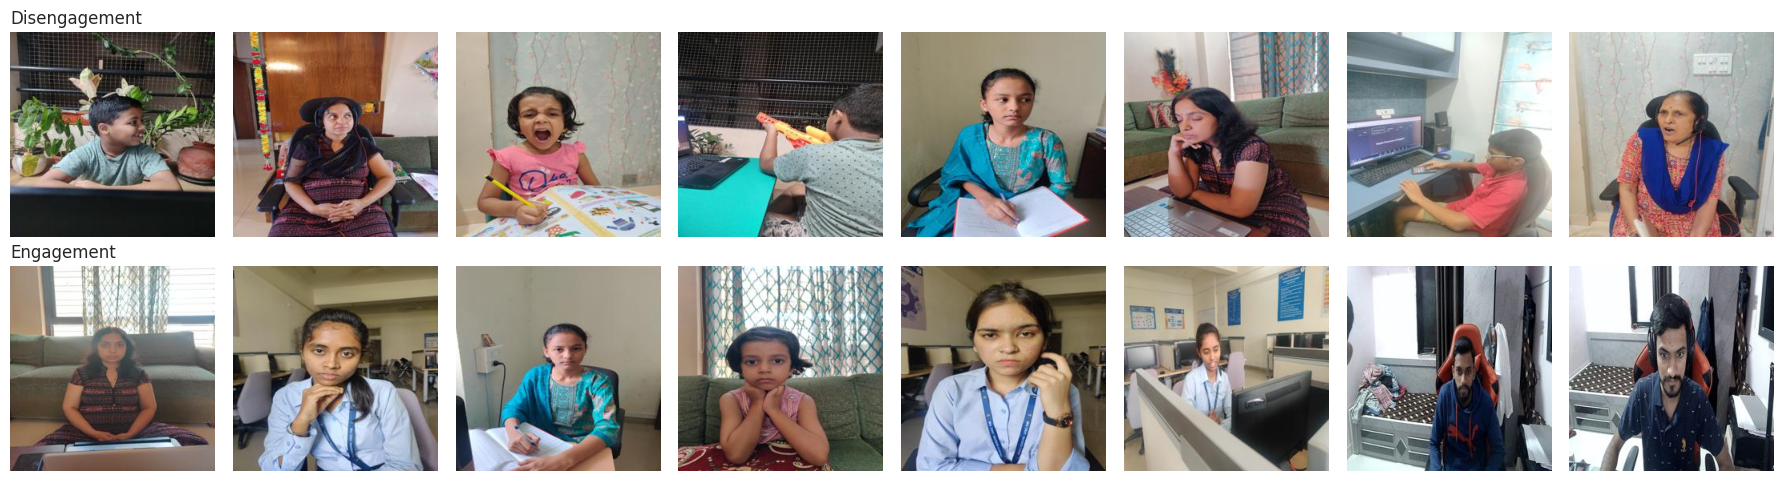

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for row, label in enumerate(CLASS_NAMES):
    sample = data[data["label"] == label].sample(8, random_state=SEED)
    for ax, rel in zip(axes[row], sample["relpath"]):
        ax.imshow(Image.open(DATA_ROOT / rel)); ax.axis("off")
    axes[row, 0].set_title(label, loc="left", fontsize=12)
plt.tight_layout(); plt.savefig("outputs/figures/sample_images.png", dpi=120); plt.show()

The samples show real home and classroom settings with learners of different ages. Engaged learners mostly face the camera or screen, or write in a book. Disengaged learners look away, yawn or play with an object. Some poses, such as resting the chin on a hand, appear in both classes, so the model has to combine gaze, posture and activity rather than rely on one cue. The same rooms appear under both labels, so the background alone does not decide the class.

### Feature 1: Age group

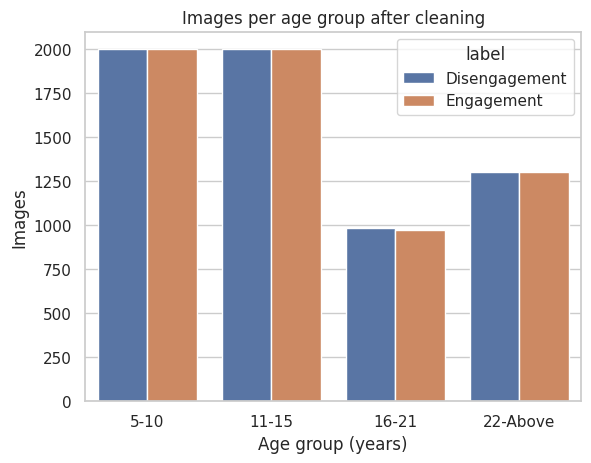

label,Disengagement,Engagement
age_group,,
5-10,2000,2000
11-15,2000,1999
16-21,985,973
22-Above,1301,1302


In [7]:
age_order = ["5-10", "11-15", "16-21", "22-Above"]
ax = sns.countplot(data=data, x="age_group", hue="label", order=age_order)
ax.set(title="Images per age group after cleaning", xlabel="Age group (years)", ylabel="Images")
plt.savefig("outputs/figures/feature_age_group.png", dpi=120, bbox_inches="tight"); plt.show()
pd.crosstab(data["age_group"], data["label"]).loc[age_order]

**Interpretation.** Children aged 5 to 10 and 11 to 15 make up 7,999 of the 12,560 images (63.7%). This suits the target users of an education platform for school children. The 16 to 21 group is the smallest at 1,958 images, because most of its boys' images were copies. Within every age group the two classes are almost equal, so a model cannot predict engagement from age alone. The smaller number of older learners means results for that group rest on fewer sessions, which Section 6 checks.

### Feature 2: Gender

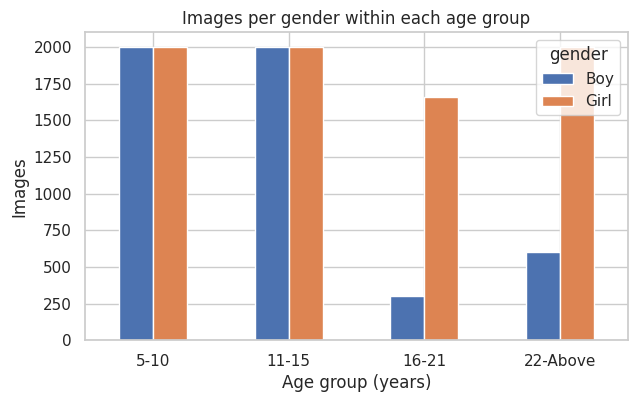

label,Disengagement,Engagement
gender,,
Boy,2451,2452
Girl,3835,3822


In [8]:
gender_age = pd.crosstab([data["age_group"]], [data["gender"]]).loc[age_order]
ax = gender_age.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set(title="Images per gender within each age group", xlabel="Age group (years)", ylabel="Images")
plt.savefig("outputs/figures/feature_gender.png", dpi=120, bbox_inches="tight"); plt.show()
pd.crosstab(data["gender"], data["label"])

**Interpretation.** After cleaning, girls make up 7,657 images (61.0%) and boys 4,903 (39.0%). The gap comes entirely from the older groups: boys and girls are equal at ages 5 to 15, but there are only 300 images of boys aged 16 to 21 against 1,658 of girls. Engagement labels stay balanced inside each gender (2,451 and 2,452 for boys), so gender does not predict the label, but the model sees fewer older boys. Section 6 reports test accuracy per gender to check whether this leads to weaker results for boys.

### Feature 3: Brightness, contrast and sharpness
Three simple measurements are taken from each greyscale image: **brightness** (average grey level, 0 to 255), **contrast** (spread of grey levels) and **sharpness** (variance of an edge filter; blurred images score low). If one of these separated the classes on its own, a model could learn lighting or camera quality instead of learner behaviour.

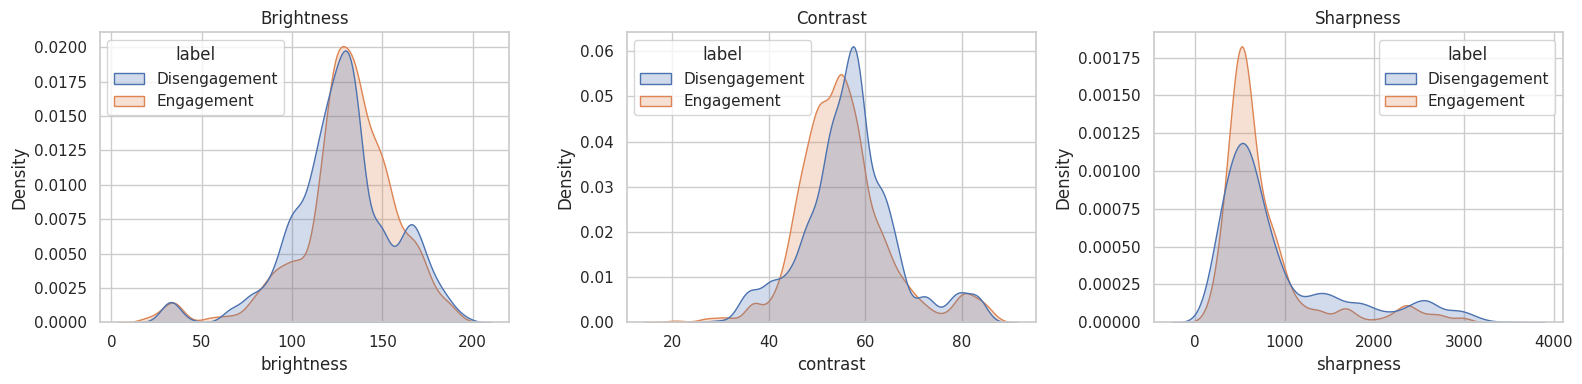

label,Disengagement,Engagement,ROC-AUC alone
brightness,127.9,132.1,0.550
contrast,57.0,54.6,0.565
sharpness,642.3,574.5,0.548


In [9]:
stats = pd.DataFrame([image_statistics(DATA_ROOT / p) for p in data["relpath"]], index=data.index)
data = data.join(stats)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["brightness", "contrast", "sharpness"]):
    sns.kdeplot(data=data, x=col, hue="label", common_norm=False, fill=True, ax=ax)
    ax.set_title(col.capitalize())
plt.tight_layout(); plt.savefig("outputs/figures/feature_image_quality.png", dpi=120); plt.show()

from sklearn.metrics import roc_auc_score
summary = data.groupby("label")[["brightness", "contrast", "sharpness"]].median().round(1).T
summary["ROC-AUC alone"] = [round(max(a, 1 - a), 3) for a in
                            (roc_auc_score(data["label_id"], data[c]) for c in summary.index)]
summary

**Interpretation.** The two classes overlap almost completely on all three measurements. Median brightness is 127.9 for disengaged and 132.1 for engaged images, and median sharpness is 642.3 against 574.5. Used alone as a classifier, each measurement reaches a ROC-AUC of only 0.55 to 0.57, where 0.5 is guessing. This is the result we want: lighting and camera quality carry almost no information about the label, so a model that performs well must be using the learner's posture, gaze and actions.

**The story these features tell.** The dataset is built around school-age children, it is balanced by label inside every age and gender group, and simple image properties do not give the answer away. Its weak points are copied files (now removed), fewer older boys, and photos grouped in sessions. These shaped the grouped split above and the fairness check in Section 6.

## 4. Model creation
**Approach: transfer learning with MobileNetV2** pretrained on ImageNet. A pretrained network already detects edges, faces and body shapes, so it needs far less data than a network trained from scratch. MobileNetV2 was chosen over larger networks because it is small (about 3.5 million parameters) and fast on a CPU, which matters for a free cloud server under a load test.

The model takes a 224 × 224 RGB image with values 0 to 255. Scaling to the range MobileNetV2 expects happens **inside** the model, so the API only needs to resize the image and cannot apply the wrong scaling.

**Optimisation techniques compared across 4 experiments:**

| Experiment | Change from previous | Why |
|---|---|---|
| E1 frozen baseline | MobileNetV2 frozen, new output layer only, Adam 0.001 | Reference point |
| E2 regularised | + augmentation (flip, rotation, zoom, contrast), dropout 0.3, L2 0.0001 | Reduce overfitting |
| E3 fine-tuned (Adam) | + unfreeze last 30 backbone layers, Adam 0.00001 | Adapt features to classroom images |
| E4 fine-tuned (SGD) | same as E3 with SGD and momentum 0.9 | Compare optimisers |

All runs use **early stopping** on validation loss (patience 4, best weights restored) and halve the learning rate when validation loss stops improving. BatchNorm layers stay frozen during fine-tuning so their statistics are not disturbed by small batches.

Finished experiments are saved with an id built from their settings. Running the cell again skips them; changing a setting trains that experiment again.

In [10]:
COMMON = dict(batch_size=32, head_epochs=15, patience=4, fine_tune_epochs=10)
EXPERIMENTS = [
    dict(name="E1_frozen_baseline", augment=False, dropout=0.0, l2=0.0, optimizer="adam", lr=1e-3,
         fine_tune_layers=0, fine_tune_lr=0.0, **COMMON),
    dict(name="E2_regularised", augment=True, dropout=0.3, l2=1e-4, optimizer="adam", lr=1e-3,
         fine_tune_layers=0, fine_tune_lr=0.0, **COMMON),
    dict(name="E3_finetune_adam", augment=True, dropout=0.3, l2=1e-4, optimizer="adam", lr=1e-3,
         fine_tune_layers=30, fine_tune_lr=1e-5, **COMMON),
    dict(name="E4_finetune_sgd", augment=True, dropout=0.3, l2=1e-4, optimizer="sgd", lr=1e-2,
         fine_tune_layers=30, fine_tune_lr=1e-3, **COMMON),
]

train_df, val_df = data[data["split"] == "train"], data[data["split"] == "val"]
test_df, new_df = data[data["split"] == "test"], data[data["split"] == "new"]

for cfg in EXPERIMENTS:
    run_experiment(cfg, train_df, val_df, DATA_ROOT)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
259/259 - 73s - 280ms/step - accuracy: 0.7583 - auc: 0.8451 - loss: 0.5019 - precision: 0.7577 - recall: 0.7392 - val_accuracy: 0.6980 - val_auc: 0.7189 - val_loss: 0.6431 - val_precision: 0.7277 - val_recall: 0.7158 - learning_rate: 0.0010
Epoch 2/15
259/259 - 12s - 44ms/step - accuracy: 0.8876 - auc: 0.9564 - loss: 0.3303 - precision: 0.8945 - recall: 0.8716 - val_accuracy: 0.7109 - val_auc: 0.7623 - val_loss: 0.6090 - val_precision: 0.7195 - val_recall: 0.7729 - learning_rate: 0.0010
Epoch 3/15
259/259 - 12s - 47ms/step - accuracy: 0.9289 - auc: 0.9806 - loss: 0.2561 - precision: 0.9294 - recall: 0.9238 - val_accuracy: 0.7406 - val_auc: 0.7624 - val_loss: 0.6378 - val_precision: 0.7925 - val_recall: 0.7122 - learning_rate: 0.0010
Epoch 4/15
259/259 - 11s - 43ms/step - accuracy: 0.9497 - auc: 0.9887 - loss: 0.2115 - precision: 0.9496 - recall: 0.9467 - val_accuracy: 0.7203 - val_auc: 0.7694 - val_loss: 0.6313 - val_precision

Epoch 1/15
259/259 - 33s - 129ms/step - accuracy: 0.6722 - auc: 0.7427 - loss: 0.5968 - precision: 0.6660 - recall: 0.6531 - val_accuracy: 0.6183 - val_auc: 0.6557 - val_loss: 0.6894 - val_precision: 0.6584 - val_recall: 0.6281 - learning_rate: 0.0010
Epoch 2/15
259/259 - 20s - 76ms/step - accuracy: 0.7761 - auc: 0.8612 - loss: 0.4653 - precision: 0.7745 - recall: 0.7608 - val_accuracy: 0.6866 - val_auc: 0.7092 - val_loss: 0.6558 - val_precision: 0.6894 - val_recall: 0.7774 - learning_rate: 0.0010
Epoch 3/15
259/259 - 22s - 84ms/step - accuracy: 0.7945 - auc: 0.8835 - loss: 0.4306 - precision: 0.7962 - recall: 0.7758 - val_accuracy: 0.6802 - val_auc: 0.7208 - val_loss: 0.6549 - val_precision: 0.7226 - val_recall: 0.6742 - learning_rate: 0.0010
Epoch 4/15
259/259 - 19s - 74ms/step - accuracy: 0.8176 - auc: 0.9007 - loss: 0.4021 - precision: 0.8145 - recall: 0.8089 - val_accuracy: 0.7084 - val_auc: 0.7297 - val_loss: 0.6548 - val_precision: 0.7003 - val_recall: 0.8163 - learning_rate: 0.

Epoch 1/15
259/259 - 25s - 98ms/step - accuracy: 0.6722 - auc: 0.7427 - loss: 0.5968 - precision: 0.6660 - recall: 0.6531 - val_accuracy: 0.6183 - val_auc: 0.6557 - val_loss: 0.6894 - val_precision: 0.6584 - val_recall: 0.6281 - learning_rate: 0.0010
Epoch 2/15
259/259 - 19s - 75ms/step - accuracy: 0.7761 - auc: 0.8612 - loss: 0.4653 - precision: 0.7745 - recall: 0.7608 - val_accuracy: 0.6866 - val_auc: 0.7092 - val_loss: 0.6558 - val_precision: 0.6894 - val_recall: 0.7774 - learning_rate: 0.0010
Epoch 3/15
259/259 - 19s - 73ms/step - accuracy: 0.7945 - auc: 0.8835 - loss: 0.4306 - precision: 0.7962 - recall: 0.7758 - val_accuracy: 0.6802 - val_auc: 0.7208 - val_loss: 0.6549 - val_precision: 0.7226 - val_recall: 0.6742 - learning_rate: 0.0010
Epoch 4/15
259/259 - 21s - 80ms/step - accuracy: 0.8176 - auc: 0.9007 - loss: 0.4021 - precision: 0.8145 - recall: 0.8089 - val_accuracy: 0.7084 - val_auc: 0.7297 - val_loss: 0.6548 - val_precision: 0.7003 - val_recall: 0.8163 - learning_rate: 0.0

Epoch 1/15
259/259 - 26s - 100ms/step - accuracy: 0.7277 - auc: 0.8069 - loss: 0.5981 - precision: 0.7182 - recall: 0.7237 - val_accuracy: 0.6347 - val_auc: 0.6861 - val_loss: 0.7786 - val_precision: 0.6481 - val_recall: 0.7267 - learning_rate: 0.0100
Epoch 2/15
259/259 - 39s - 152ms/step - accuracy: 0.7857 - auc: 0.8669 - loss: 0.5025 - precision: 0.7812 - recall: 0.7765 - val_accuracy: 0.6376 - val_auc: 0.7395 - val_loss: 0.7620 - val_precision: 0.6277 - val_recall: 0.8299 - learning_rate: 0.0100
Epoch 3/15
259/259 - 21s - 82ms/step - accuracy: 0.7881 - auc: 0.8717 - loss: 0.5097 - precision: 0.7827 - recall: 0.7807 - val_accuracy: 0.6644 - val_auc: 0.7307 - val_loss: 0.8127 - val_precision: 0.6430 - val_recall: 0.8688 - learning_rate: 0.0100
Epoch 4/15
259/259 - 21s - 80ms/step - accuracy: 0.8086 - auc: 0.8873 - loss: 0.4714 - precision: 0.8053 - recall: 0.7997 - val_accuracy: 0.6802 - val_auc: 0.7114 - val_loss: 0.7796 - val_precision: 0.7011 - val_recall: 0.7240 - learning_rate: 0

## 5. Model selection on the validation set
The experiment table records the settings, training time and validation metrics (at a 0.5 threshold) of every run. The best experiment is chosen **automatically** by validation F1, with validation ROC-AUC as the tie-breaker. The test set plays no part in this choice.

In [11]:
results = pd.read_csv("outputs/experiments.csv").drop_duplicates("config_id", keep="last")
cols = ["name", "epochs_run", "train_minutes", "train_accuracy_last", "val_accuracy", "val_precision",
        "val_recall", "val_f1", "val_roc_auc", "val_loss"]
display(results[cols].round(4))

best = results.sort_values(["val_f1", "val_roc_auc"], ascending=False).iloc[0]
print("Selected:", best["name"], "->", best["model_file"])

,name,epochs_run,train_minutes,train_accuracy_last,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_loss
0,E1_frozen_baseline,6,2.3,0.9679,0.7109,0.7195,0.7729,0.7452,0.7623,0.6090
1,E2_regularised,10,3.6,0.8492,0.7089,0.7469,0.7077,0.7268,0.7446,0.6444
2,E3_finetune_adam,15,5.7,0.9754,0.7045,0.7138,0.7674,0.7396,0.7778,0.6090
3,E4_finetune_sgd,22,8.5,0.5086,0.5470,0.5470,1.0000,0.7072,0.4997,0.6910


Selected: E1_frozen_baseline -> models/experiments/E1_frozen_baseline_719b9f4f54.h5


**Findings.**
- **E1 frozen baseline** reached the highest validation F1 (0.745) with accuracy 0.711 and ROC-AUC 0.762. Early stopping ended it after 6 epochs, in 2.3 minutes.
- **E2 regularised:** adding augmentation, dropout and L2 lowered training accuracy from 0.968 to 0.849, so the model memorised less, but validation results did not improve (F1 0.727, ROC-AUC 0.745). Regularisation narrowed the gap between training and validation without making the model better on new sessions.
- **E3 fine-tuned (Adam):** unfreezing the last 30 layers gave the best ranking of probabilities (ROC-AUC 0.778, the highest of all runs) and F1 0.740, just below E1. Its training accuracy rose to 0.975, so fine-tuning also increased overfitting.
- **E4 fine-tuned (SGD) failed.** During fine-tuning its training accuracy fell to about 0.51 and validation ROC-AUC to 0.500: the model predicts "engaged" for every image (validation recall 1.000). The SGD fine-tuning learning rate (0.001) was 100 times the Adam one, and it destroyed the pretrained features. Its F1 of 0.707 looks acceptable only because predicting one class for everything still gives reasonable F1 when that class is slightly larger. ROC-AUC exposes the failure, which is why both metrics are reported.

**Selected model: E1**, by validation F1 (0.745 against 0.740 for E3). E3 ranks probabilities better, so the two are close; F1 was fixed as the selection rule before training and is kept.

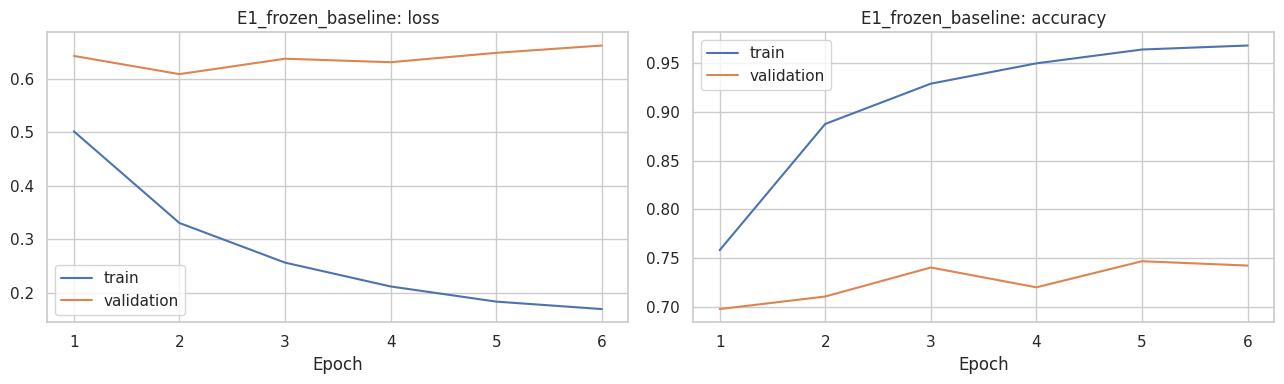

In [12]:
history = pd.read_csv(Path(best["model_file"]).with_name(Path(best["model_file"]).stem + "_history.csv"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history["epoch"], history[metric], label="train")
    ax.plot(history["epoch"], history[f"val_{metric}"], label="validation")
    ax.set(title=f"{best['name']}: {metric}", xlabel="Epoch"); ax.legend()
plt.tight_layout(); plt.savefig("outputs/figures/learning_curves.png", dpi=120); plt.show()

**Bias and variance.** E1 was at its best after epoch 2 (training accuracy 0.888, validation accuracy 0.711, validation loss 0.609). From then on training loss kept falling, to 0.169 at epoch 6 with training accuracy 0.968, while validation loss rose to 0.663. The gap of more than 20 accuracy points between training and validation shows **high variance (overfitting)**: the model learns the training sessions well but transfers only part of that to new learners and rooms. Early stopping restored the epoch 2 weights, which limits the damage but cannot remove the gap.

### 5.1 Decision threshold
The model outputs a probability of engagement. The default cut-off of 0.5 is not always best, so the threshold with the highest F1 is found on the **validation** set and then fixed.

In [13]:
import keras
best_model = keras.models.load_model(best["model_file"])
val_ds = make_tf_dataset([DATA_ROOT / p for p in val_df["relpath"]], val_df["label_id"])
val_proba = predict_proba(best_model, val_ds)
THRESHOLD = best_threshold(val_df["label_id"], val_proba)
print("Chosen threshold:", THRESHOLD)
print("Validation F1 at 0.5:", round(classification_metrics(val_df["label_id"], val_proba, 0.5)["f1"], 4),
      "| at chosen threshold:", round(classification_metrics(val_df["label_id"], val_proba, THRESHOLD)["f1"], 4))

Chosen threshold: 0.48
Validation F1 at 0.5: 0.7452 | at chosen threshold: 0.7504


**Findings.** The best threshold on the validation set is 0.48, close to the default. It raises validation F1 only slightly, from 0.745 to 0.750, so the model's probabilities are already centred near 0.5.

## 6. Final evaluation on the test set
The selected model and threshold are now applied **once** to the test set, which no earlier step has used. Six metrics are reported:
- **Accuracy**: share of all images classified correctly
- **Precision**: of the learners flagged as engaged, the share who really were
- **Recall**: of the truly engaged learners, the share the model found
- **F1**: balance of precision and recall
- **ROC-AUC**: how well the probabilities rank engaged above disengaged, at any threshold
- **Loss** (binary cross-entropy): how confident and correct the probabilities are

A **majority-class baseline** (always predict the larger class) shows what "no learning" scores.

,test
accuracy,0.6483
precision,0.6597
recall,0.6324
f1,0.6457
roc_auc,0.6917
loss,0.6951


Majority-class baseline accuracy: 0.4931


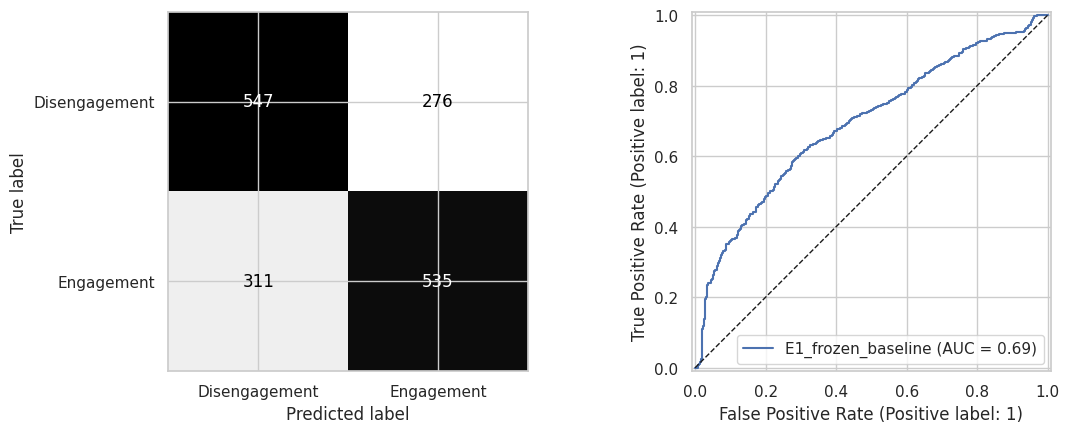

In [14]:
test_ds = make_tf_dataset([DATA_ROOT / p for p in test_df["relpath"]], test_df["label_id"])
test_proba = predict_proba(best_model, test_ds)
test_metrics = classification_metrics(test_df["label_id"], test_proba, THRESHOLD)

majority = int(train_df["label_id"].mode()[0])
baseline_acc = (test_df["label_id"] == majority).mean()
display(pd.Series({k: v for k, v in test_metrics.items() if k not in ("tn", "fp", "fn", "tp")}).round(4).to_frame("test"))
print("Majority-class baseline accuracy:", round(baseline_acc, 4))

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(test_df["label_id"], (test_proba >= THRESHOLD).astype(int),
                                        display_labels=CLASS_NAMES, cmap="Greys", ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(test_df["label_id"], test_proba, ax=axes[1], name=best["name"])
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
plt.tight_layout(); plt.savefig("outputs/figures/test_confusion_roc.png", dpi=120); plt.show()

**Findings.** On the 1,669 unseen test images the model scores accuracy 0.648, precision 0.660, recall 0.632, F1 0.646, ROC-AUC 0.692 and loss 0.695. Always predicting the majority class gives accuracy 0.493, so the model is 15.5 points better than no learning.

The two kinds of error are close in number: 311 engaged learners were marked disengaged (false negatives) and 276 disengaged learners were marked engaged (false positives); 547 and 535 were classified correctly. A loss of 0.695 is close to 0.693, the loss of a model that always outputs 0.5, which means the probabilities are mostly near the middle: the model separates the classes, but with low confidence.

Test accuracy (0.648) is lower than validation accuracy (0.711). The validation set was used for early stopping, model choice and the threshold, so its scores are slightly optimistic; the test score is the fair estimate of performance on new learners.

### 6.1 Errors by group (fairness check)
Section 3 showed fewer images of older boys. The cell below reports test accuracy and recall for each age group and gender to see whether the model is weaker for any group.

In [15]:
scored = test_df.assign(proba=test_proba, pred=(test_proba >= THRESHOLD).astype(int))
def group_scores(g):
    m = classification_metrics(g["label_id"], g["proba"].to_numpy(), THRESHOLD)
    return pd.Series({"images": len(g), "accuracy": m["accuracy"], "recall": m["recall"], "f1": m["f1"]})
display(scored.groupby("age_group").apply(group_scores).loc[age_order].round(3))
display(scored.groupby("gender").apply(group_scores).round(3))

/tmp/ipykernel_1683/2630211166.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(scored.groupby("age_group").apply(group_scores).loc[age_order].round(3))


,images,accuracy,recall,f1
age_group,,,,
5-10,566.0,0.631,0.564,0.602
11-15,539.0,0.675,0.696,0.700
16-21,297.0,0.589,0.739,0.619
22-Above,267.0,0.697,0.532,0.646


/tmp/ipykernel_1683/2630211166.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(scored.groupby("gender").apply(group_scores).round(3))


,images,accuracy,recall,f1
gender,,,,
Boy,619.0,0.727,0.785,0.755
Girl,1050.0,0.602,0.534,0.568


**Findings.** The weakest age group is **16 to 21 years**, with accuracy 0.589 on 297 test images; the strongest is 22 and above (0.697 on 267 images). Recall, the share of engaged learners found, is lowest for 22 and above (0.532) and 5 to 10 (0.564).

The gender result is the opposite of what the image counts suggested in Section 3: accuracy is **0.727 for boys** (619 images) but **0.602 for girls** (1,050 images), although girls have more training images. Sample size therefore does not explain the gap. Each test group holds only a few sessions of about 20 images each (297 images is roughly 15 sessions), so these per-group figures depend heavily on which learners happen to be in the test set and should be read as warning signs, not settled differences.

## 7. Saving the model
The selected model is copied to `models/engagement_mobilenetv2.h5`. Its metadata file stores the class names, input size, threshold, test metrics and version number. The API and the retraining process both read these two files.

In [16]:
if not METADATA_PATH.exists():
    metadata = save_production_model(best["model_file"], THRESHOLD, test_metrics, version=1,
                                     extra={"experiment": best["name"]})
else:
    metadata = json.loads(METADATA_PATH.read_text())
    print("Production model already saved; version", metadata["version"])
print(json.dumps(metadata, indent=2))

{
  "version": 1,
  "class_names": [
    "Disengagement",
    "Engagement"
  ],
  "positive_class": "Engagement",
  "img_size": 224,
  "threshold": 0.48,
  "metrics": {
    "accuracy": 0.6482923906530856,
    "precision": 0.6596794081381011,
    "recall": 0.6323877068557919,
    "f1": 0.6457453228726614,
    "roc_auc": 0.6917435778116733,
    "loss": 0.69508892295929,
    "tn": 547.0,
    "fp": 276.0,
    "fn": 311.0,
    "tp": 535.0
  },
  "trained_at": "2026-11-22T14:32:29+00:00",
  "experiment": "E1_frozen_baseline"
}


## 8. Prediction functions
`EngagementPredictor` in `src/prediction.py` loads the saved model and metadata and accepts a file path, raw bytes or an uploaded file. It returns the label, the probability of engagement and the model version. The same class serves the API.

A small labelled sample from the test split is copied to `data/test/` for the prediction demo, and a sample from the "new" split to `data/train/` as the upload batch for the retraining demo.

In [17]:
import shutil
def export_sample(df, folder, per_class, seed=SEED):
    for label in CLASS_NAMES:
        out = Path(folder) / label
        out.mkdir(parents=True, exist_ok=True)
        for rel in df[df["label"] == label].sample(per_class, random_state=seed)["relpath"]:
            shutil.copy(DATA_ROOT / rel, out / Path(rel).name)

export_sample(test_df, "data/test", per_class=10)
export_sample(new_df, "data/train", per_class=40)

predictor = EngagementPredictor()
demo = sorted(Path("data/test").glob("*/*.jpg"))
preds = predictor.predict_batch(demo)
demo_table = pd.DataFrame({"file": [p.name for p in demo], "true": [p.parent.name for p in demo],
                           "predicted": [r["label"] for r in preds],
                           "probability_engaged": [r["probability_engaged"] for r in preds]})
print("Correct:", (demo_table["true"] == demo_table["predicted"]).sum(), "of", len(demo_table))
demo_table

Correct: 12 of 20


,file,true,predicted,probability_engaged
0,DISENG_11_15_BOY_404.jpg,Disengagement,Engagement,0.6097
1,DISENG_11_15_BOY_799.jpg,Disengagement,Disengagement,0.0712
2,DISENG_11_15_GIRL_34.jpg,Disengagement,Engagement,0.6927
3,DISENG_11_15_GIRL_35.jpg,Disengagement,Engagement,0.6831
4,DISENG_16_21_GIRL_348.jpg,Disengagement,Engagement,0.6653
5,DISENG_16_21_GIRL_406.jpg,Disengagement,Disengagement,0.2879
6,DISENG_5_10_Girl_138.jpg,Disengagement,Disengagement,0.4348
7,DISENG_5_10_Girl_834.jpg,Disengagement,Engagement,0.6942
8,DISENT_5_10_BOY_481.jpg,Disengagement,Disengagement,0.4556
9,DISENT_5_10_BOY_858.jpg,Disengagement,Disengagement,0.1417


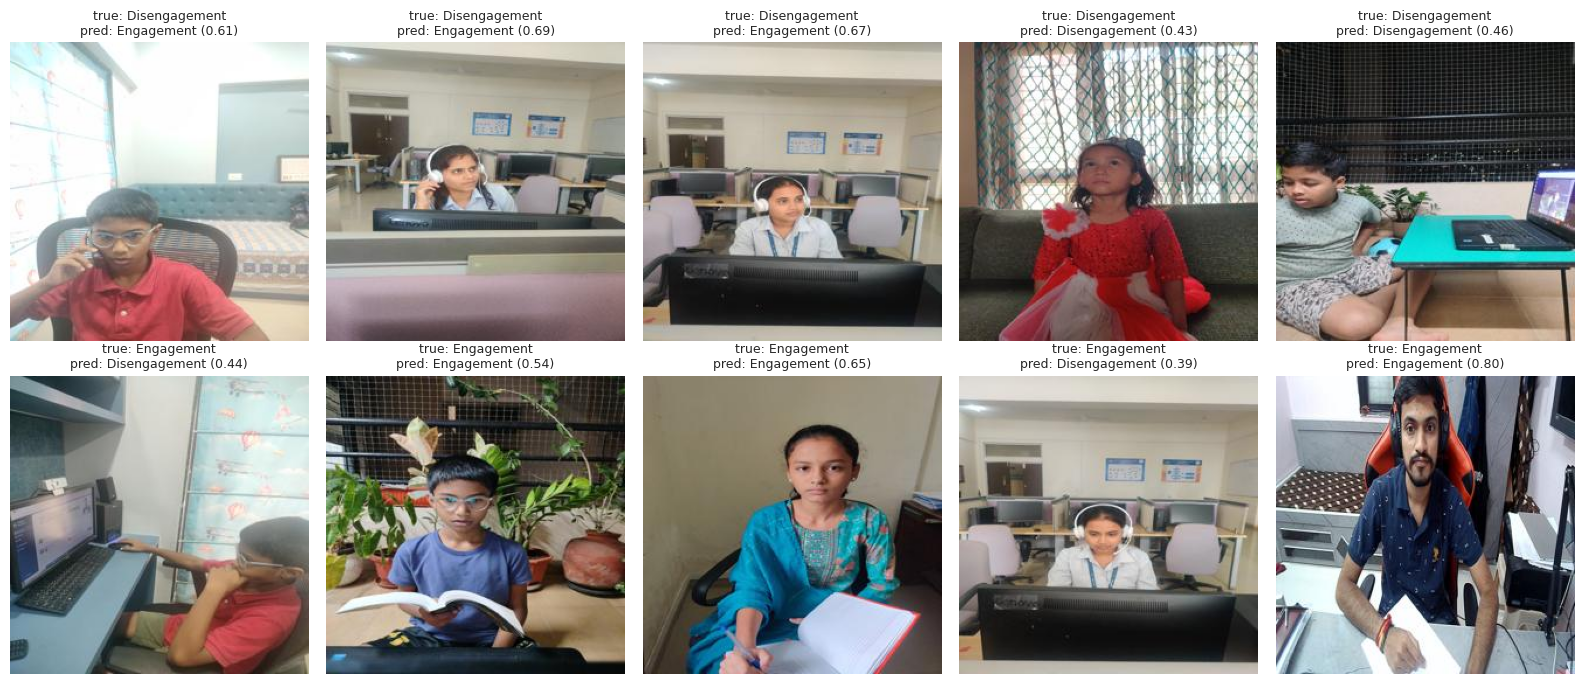

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, path, r in zip(axes.ravel(), demo[::2], preds[::2]):
    ax.imshow(Image.open(path)); ax.axis("off")
    ax.set_title(f"true: {path.parent.name}\npred: {r['label']} ({r['probability_engaged']:.2f})", fontsize=9)
plt.tight_layout(); plt.savefig("outputs/figures/prediction_demo.png", dpi=120); plt.show()

**Findings.** The model classified 12 of the 20 demo images correctly (60%), in line with its test accuracy: 7 of 10 engaged and 5 of 10 disengaged images. Most probabilities lie between 0.39 and 0.70, which matches the low confidence seen in the test loss. The clearest cases are a disengaged 11 to 15 year old boy (probability of engagement 0.071) and an engaged learner aged 22 and above (0.804).

## 9. Retraining from the saved model
This is the process the retrain button runs in the deployed app:
1. **Upload:** new labelled images arrive (here, the 604 images of the "new" split, which no model has seen).
2. **Preprocess:** the same `make_tf_dataset` resizing used in training.
3. **Retrain:** the saved production model is loaded as the starting point. It is fine-tuned on the new images plus 1,000 randomly chosen earlier training images, so it does not forget what it learnt before, using a low learning rate (0.00001).
4. **Compare and promote:** old and new model are scored on the same validation set. The new model replaces the old one only if its validation F1 has not dropped by more than 0.01. The old file is kept as a backup.

**Trigger:** in the app, retraining starts when the user presses the button, or automatically once 200 or more new images have been uploaded since the last retrain.

In [19]:
FORCE_RETRAIN = False
if json.loads(METADATA_PATH.read_text())["version"] == 1 or FORCE_RETRAIN:
    retrain_result = retrain(new_df=new_df, val_df=val_df, data_root=DATA_ROOT, replay_df=train_df,
                             replay_size=1000, fine_tune_layers=30, lr=1e-5, epochs=5)
    Path("outputs/retrain_result.json").write_text(json.dumps(retrain_result, indent=2, default=float))
else:
    retrain_result = json.loads(Path("outputs/retrain_result.json").read_text())

compare = pd.DataFrame({"before retraining": retrain_result["old_val"],
                        "after retraining": retrain_result["new_val"]}).loc[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "loss"]]
print("Promoted:", retrain_result["promoted"], "| training images:", retrain_result["train_images"],
      "| minutes:", retrain_result["minutes"])
compare.round(4)

Epoch 1/5
51/51 - 33s - 643ms/step - accuracy: 0.9152 - auc: 0.9742 - loss: 0.2555 - precision: 0.9075 - recall: 0.9275 - val_accuracy: 0.6832 - val_auc: 0.7518 - val_loss: 0.6456 - val_precision: 0.6807 - val_recall: 0.7928 - learning_rate: 1.0000e-05
Epoch 2/5
51/51 - 5s - 95ms/step - accuracy: 0.9663 - auc: 0.9941 - loss: 0.1460 - precision: 0.9567 - recall: 0.9779 - val_accuracy: 0.7099 - val_auc: 0.7653 - val_loss: 0.6403 - val_precision: 0.7323 - val_recall: 0.7403 - learning_rate: 1.0000e-05
Epoch 3/5
51/51 - 4s - 86ms/step - accuracy: 0.9825 - auc: 0.9986 - loss: 0.1028 - precision: 0.9781 - recall: 0.9877 - val_accuracy: 0.7153 - val_auc: 0.7782 - val_loss: 0.6351 - val_precision: 0.7253 - val_recall: 0.7719 - learning_rate: 1.0000e-05
Epoch 4/5
51/51 - 4s - 84ms/step - accuracy: 0.9869 - auc: 0.9995 - loss: 0.0772 - precision: 0.9841 - recall: 0.9902 - val_accuracy: 0.7099 - val_auc: 0.7746 - val_loss: 0.6533 - val_precision: 0.7392 - val_recall: 0.7258 - learning_rate: 1.000

Promoted: True | training images: 1604 | minutes: 1.1


,before retraining,after retraining
accuracy,0.7119,0.7178
precision,0.7131,0.7072
recall,0.7919,0.8262
f1,0.7504,0.7621
roc_auc,0.7623,0.7781
loss,0.6090,0.6351


**Findings.** Retraining used 1,604 images (the 604 new images plus 1,000 earlier training images) and took 1.1 minutes for 5 epochs. On the validation set, F1 rose from 0.750 to 0.762, recall from 0.792 to 0.826 and ROC-AUC from 0.762 to 0.778, while precision fell slightly from 0.713 to 0.707. F1 improved, so the new model was **promoted** to version 2 and version 1 was kept as a backup. Training accuracy reached 0.997 by the last epoch, so the model again fits its training images far better than new ones.

For monitoring only (no choice depends on it), the current production model is scored on the test set again after retraining:

In [20]:
current = EngagementPredictor()
after_proba = predict_proba(current.model, test_ds)
after = classification_metrics(test_df["label_id"], after_proba, current.threshold)
pd.DataFrame({"version 1": test_metrics, f"version {current.metadata['version']}": after}).loc[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "loss"]].round(4)

,version 1,version 2
accuracy,0.6483,0.6537
precision,0.6597,0.6614
recall,0.6324,0.6489
f1,0.6457,0.6551
roc_auc,0.6917,0.7273
loss,0.6951,0.7098


**Findings.** On the test set, version 2 improves on version 1 in accuracy (0.648 to 0.654), F1 (0.646 to 0.655) and ROC-AUC (0.692 to 0.727). Loss rose from 0.695 to 0.710, meaning that some of its confident predictions are wrong. The retraining process therefore works end to end: new data is preprocessed, the saved model is fine-tuned, compared on validation data and promoted only when it is not worse.

## 10. Limitations
- **Moderate accuracy on new learners.** Test accuracy is 0.648 (version 1) and 0.654 (version 2), against 0.97 or more on training images. The model has not learnt a general sign of engagement that transfers to unseen sessions. More learners (rather than more photos of the same learners), several frames per prediction, or cropping the learner from the background are the most likely ways to improve it.
- **Data origin.** Version 1 of this dataset was removed from Mendeley Data for "suspected copyright infringement". The Zenodo copy used here is published under CC BY 4.0, but the authors do not state how the images were collected or whether consent was given. The images are therefore kept out of the public repository, apart from 100 sample images used for the demo.
- **Images of children.** A real deployment would need consent from parents and schools, local storage of images, and clear rules on who sees the predictions.
- **No learner IDs.** Groups are built from image similarity. The same learner photographed in two different sessions may still appear in two splits, so test scores may be slightly optimistic.
- **One frame is a simplification.** Engagement changes over time; a single photo can catch a learner glancing away for a second. A video dataset with many learners, such as DAiSEE (Gupta et al., 2016; 112 users), would allow a model that looks at several seconds of behaviour.
- **Uneven groups.** Older boys are under-represented after removing copies (300 images aged 16 to 21).

## References
1. P. Chate and K. Patil, "E-learning Student Engagement and Disengagement Image Dataset for Educational Research," Zenodo, 2025. doi: 10.5281/zenodo.16731734.
2. P. Chate and K. Patil, "Student Engagement and Disengagement Image Dataset for Educational Research," *Educational Administration: Theory and Practice*, vol. 30, no. 10, pp. 2599–2604, 2024. doi: 10.67145/kuey.v30i10.10736.
3. M. Sandler, A. Howard, M. Zhu, A. Zhmoginov and L.-C. Chen, "MobileNetV2: Inverted Residuals and Linear Bottlenecks," in *Proc. IEEE/CVF CVPR*, 2018, pp. 4510–4520.
4. A. Gupta, A. D'Cunha, K. Awasthi and V. Balasubramanian, "DAiSEE: Towards User Engagement Recognition in the Wild," arXiv:1609.01885, 2016.